# Hito 1 · Exploración guiada de COVID-19
Se estudian los 161 reportes del 22-ene al 30-jun-2020. Esta exploración conserva
todas las filas: no deduplica, imputa ni construye la capa limpia del Hito 2.
El .py es la fuente de las mismas celdas y explicaciones del notebook.
Por defecto se usa la caché local o se lee el clon hermano sin modificarlo.


In [1]:
import datetime as dt
import hashlib
import io
import os
import time
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.request import urlopen
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pandas as pd

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 160)


def mostrar(objeto):
    """Salida legible en Jupyter y en la terminal."""
    try:
        from IPython import get_ipython
        from IPython.display import Image, display
        if get_ipython() is not None:
            if isinstance(objeto, Path) and objeto.suffix == ".png":
                display(Image(filename=str(objeto)))
            else:
                display(objeto)
            return
    except ImportError:
        pass
    print(objeto.to_string() if isinstance(objeto, (pd.DataFrame, pd.Series)) else objeto)


def localizar_proyecto():
    indicada = os.environ.get("COVID_HITO1_ROOT")
    if indicada:
        candidatos = [Path(indicada).expanduser().resolve()]
    else:
        inicio = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
        candidatos = []
        for carpeta in (inicio, *inicio.parents):
            candidatos.extend([carpeta, carpeta / "proyecto gestion"])
    for carpeta in candidatos:
        if (carpeta / "notebooks/00_exploracion.py").is_file() and (carpeta / "README.md").is_file():
            return carpeta
    raise FileNotFoundError("Define COVID_HITO1_ROOT con la ruta de proyecto gestion.")


PROJECT = localizar_proyecto()
RAW = PROJECT / "data/raw/daily_reports"
ORIGINAL = PROJECT.parent / "COVID-19/csse_covid_19_data/csse_covid_19_daily_reports"
FIGS = PROJECT / "data/figs"
PROFILE = PROJECT / "data/profile"
PERMITIR_DESCARGA = os.environ.get("COVID_HITO1_DESCARGAR", "0") == "1"
FECHAS = pd.date_range("2020-01-22", "2020-06-30", freq="D")
URL_BASE = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_daily_reports/"
print("Proyecto:", PROJECT, "| reportes esperados:", len(FECHAS), "| red:", PERMITIR_DESCARGA)


Proyecto: C:\Users\beaaa\OneDrive\Documents\Gestion-Datos-COVID19\proyecto gestion | reportes esperados: 161 | red: False


## 1. Exploración inicial
Cada fila es un territorio publicado por JHU: puede ser un país o una provincia.
Confirmed, Deaths y Recovered son acumulados. Los tipos float inferidos pueden
reflejar celdas vacías; no significan necesariamente conteos fraccionarios.


In [2]:
MAPA_COLUMNAS = {
    "Province/State": "provincia_estado", "Province_State": "provincia_estado",
    "Country/Region": "region_pais", "Country_Region": "region_pais",
    "Last Update": "ultima_actualizacion", "Last_Update": "ultima_actualizacion",
    "Latitude": "latitud", "Lat": "latitud", "Longitude": "longitud", "Long_": "longitud",
    "FIPS": "fips", "Admin2": "admin2", "Confirmed": "confirmados", "Deaths": "fallecidos",
    "Recovered": "recuperados", "Active": "activos", "Combined_Key": "clave_combinada",
    "Incidence_Rate": "tasa_incidentes", "Incident_Rate": "tasa_incidentes",
    "Case-Fatality_Ratio": "tasa_letalidad", "Case_Fatality_Ratio": "tasa_letalidad",
}
ESQUEMA_1 = {"Province/State", "Country/Region", "Last Update", "Confirmed", "Deaths", "Recovered"}
ESQUEMA_3 = {"FIPS", "Admin2", "Province_State", "Country_Region", "Last_Update", "Lat", "Long_",
             "Confirmed", "Deaths", "Recovered", "Active", "Combined_Key"}
ESQUEMAS = {1: ESQUEMA_1, 2: ESQUEMA_1 | {"Latitude", "Longitude"}, 3: ESQUEMA_3,
            4: ESQUEMA_3 | {"Incidence_Rate", "Case-Fatality_Ratio"},
            5: ESQUEMA_3 | {"Incident_Rate", "Case_Fatality_Ratio"}}


def clasificar_esquema(columnas):
    for etapa, esperadas in ESQUEMAS.items():
        if set(columnas) == esperadas:
            return etapa
    raise ValueError(f"Cabecera desconocida; revisar sin descartar columnas: {list(columnas)}")


def leer_csv(datos, nombre):
    # Solo el texto vacío es NA; no interpretar códigos territoriales como números.
    tabla = pd.read_csv(io.BytesIO(datos), dtype="string", keep_default_na=False)
    clasificar_esquema(tabla.columns)
    if tabla.empty:
        raise ValueError(f"Reporte vacío: {nombre}")
    return tabla.replace("", pd.NA)


def obtener_reporte(nombre):
    """Valida el caché; no sobrescribe crudos ni omite días con errores."""
    for carpeta, fuente in [(RAW, "cache"), (ORIGINAL, "clon_local")]:
        archivo = carpeta / nombre
        if archivo.is_file():
            datos = archivo.read_bytes()
            return leer_csv(datos, nombre), datos, fuente
    if not PERMITIR_DESCARGA:
        raise FileNotFoundError(f"Falta {nombre} en caché y clon local. Carga detenida. "
                                "Para habilitar red usa COVID_HITO1_DESCARGAR=1.")
    for intento in range(3):
        try:
            with urlopen(URL_BASE + nombre, timeout=30) as respuesta:
                datos = respuesta.read()
            tabla = leer_csv(datos, nombre)
            RAW.mkdir(parents=True, exist_ok=True)
            with (RAW / nombre).open("xb") as salida:
                salida.write(datos)
            return tabla, datos, "descarga"
        except HTTPError as error:
            if error.code == 404:
                raise FileNotFoundError(f"Reporte {nombre}: HTTP 404; no se omite el día.") from error
            if intento == 2:
                raise
        except (URLError, TimeoutError):
            if intento == 2:
                raise
        time.sleep(2)
    raise RuntimeError(nombre)


pr1_texto, primer_contenido, _ = obtener_reporte("01-22-2020.csv")
# Inferencia solo para describir el primer CSV; la ingesta usa texto.
pr1 = pd.read_csv(io.BytesIO(primer_contenido))
mostrar(pr1.head())
print(f"Primer reporte: {pr1.shape[0]} filas × {pr1.shape[1]} columnas")
mostrar(pr1.dtypes.rename("tipo_inferido").to_frame())
assert pr1.shape == (76, 6)


,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
1,Beijing,Mainland China,1/22/2020 17:00,14.0,NaN,NaN
2,Chongqing,Mainland China,1/22/2020 17:00,6.0,NaN,NaN
3,Fujian,Mainland China,1/22/2020 17:00,1.0,NaN,NaN
4,Gansu,Mainland China,1/22/2020 17:00,NaN,NaN,NaN


Primer reporte: 76 filas × 6 columnas


,tipo_inferido
Province/State,object
Country/Region,object
Last Update,object
Confirmed,float64
Deaths,float64
Recovered,float64


## 2. Valores faltantes
Provincia vacía puede indicar una fila nacional. Un conteo vacío no demuestra
cero casos: significa que la celda no informa el valor. La causa exacta no se
deduce del CSV. Coordenadas y Admin2 aún no existen en el primer esquema;
más adelante se separan estas ausencias estructurales de los vacíos de origen.


In [3]:
interpretacion = {
    "Province/State": "Sin provincia especificada; puede ser una fila nacional.",
    "Country/Region": "País o entidad; revisar si falta.",
    "Last Update": "Momento de actualización declarado por JHU.",
    "Confirmed": "Conteo no informado en la celda; no equivale a cero.",
    "Deaths": "Conteo no informado en la celda; no equivale a cero.",
    "Recovered": "Conteo no informado en la celda; no equivale a cero.",
}
nulos = pr1.isna().sum().to_frame("nulos")
nulos["porcentaje"] = (100 * nulos.nulos / len(pr1)).round(2)
nulos["interpretacion"] = [interpretacion[c] for c in nulos.index]
mostrar(nulos)
assert nulos.nulos.to_dict() == {"Province/State": 12, "Country/Region": 0, "Last Update": 0,
                                "Confirmed": 10, "Deaths": 37, "Recovered": 37}


,nulos,porcentaje,interpretacion
Province/State,12,15.79,Sin provincia especificada; puede ser una fila...
Country/Region,0,0.00,País o entidad; revisar si falta.
Last Update,0,0.00,Momento de actualización declarado por JHU.
Confirmed,10,13.16,Conteo no informado en la celda; no equivale a...
Deaths,37,48.68,Conteo no informado en la celda; no equivale a...
Recovered,37,48.68,Conteo no informado en la celda; no equivale a...


## 3. Estandarización y fechas
La fecha del reporte sale del archivo y no se sustituye por Last_Update.
Se conserva el texto original de actualización con hora; no se inventa zona
horaria. Una conversión inválida detiene la ejecución e informa su origen.
FIPS permanece como texto para conservar ceros iniciales.


In [4]:
NUMERICAS = ["confirmados", "fallecidos", "recuperados", "activos", "latitud", "longitud",
             "tasa_incidentes", "tasa_letalidad"]
FORMATOS = ("%m/%d/%y %H:%M", "%m/%d/%Y %H:%M", "%m/%d/%y %H:%M:%S",
            "%m/%d/%Y %H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y-%m-%dT%H:%M:%S", "%Y-%m-%d %H:%M")


def estandarizar(crudo, nombre):
    etapa = clasificar_esquema(crudo.columns)
    tabla = crudo.rename(columns=MAPA_COLUMNAS).copy()
    if not tabla.columns.is_unique:
        raise ValueError(f"Colisión de nombres en {nombre}")
    texto = tabla.ultima_actualizacion.str.strip()
    fecha = pd.Series(pd.NaT, index=tabla.index, dtype="datetime64[ns]")
    for formato in FORMATOS:
        pendientes = fecha.isna() & texto.notna()
        fecha.loc[pendientes] = pd.to_datetime(texto[pendientes], format=formato, errors="coerce")
    invalidas = texto.notna() & fecha.isna()
    if invalidas.any():
        raise ValueError(f"Fechas inválidas en {nombre}: {texto[invalidas].head().to_dict()}")
    tabla["ultima_actualizacion_original"] = tabla.ultima_actualizacion.copy()
    tabla["ultima_actualizacion"] = fecha.dt.strftime("%Y-%m-%d").astype("string")
    for columna in NUMERICAS:
        if columna not in tabla:
            continue
        original = tabla[columna]
        numero = pd.to_numeric(original, errors="coerce")
        invalidos = original.notna() & numero.isna()
        if invalidos.any():
            raise ValueError(f"Números inválidos en {nombre}/{columna}: {original[invalidos].head().to_dict()}")
        tabla[columna] = numero
    tabla["fecha_reporte"] = dt.datetime.strptime(nombre, "%m-%d-%Y.csv").date().isoformat()
    tabla["etapa"] = etapa
    tabla["archivo_origen"] = nombre
    # Número de registro de datos, después de la cabecera; no línea física del CSV.
    tabla["fila_origen"] = range(1, len(tabla) + 1)
    return tabla


pr1_std = estandarizar(pr1_texto, "01-22-2020.csv")
mostrar(pr1_std[["region_pais", "provincia_estado", "ultima_actualizacion_original",
                 "ultima_actualizacion", "fecha_reporte"]].head())
assert all(clasificar_esquema(cols) == etapa for etapa, cols in ESQUEMAS.items())


,region_pais,provincia_estado,ultima_actualizacion_original,ultima_actualizacion,fecha_reporte
0,Mainland China,Anhui,1/22/2020 17:00,2020-01-22,2020-01-22
1,Mainland China,Beijing,1/22/2020 17:00,2020-01-22,2020-01-22
2,Mainland China,Chongqing,1/22/2020 17:00,2020-01-22,2020-01-22
3,Mainland China,Fujian,1/22/2020 17:00,2020-01-22,2020-01-22
4,Mainland China,Gansu,1/22/2020 17:00,2020-01-22,2020-01-22


## 4. Unificación enero–junio de 2020
Se exige cada día: no se omiten errores. El inventario muestra origen, filas y
SHA-256; cada fila conserva su archivo y número de registro. Hay cuatro esquemas
y tres transiciones en esta ventana: 1-mar, 22-mar y 29-may. El esquema 5 se
reconoce, pero sus datos no se cargan en el Hito 1.


In [5]:
partes, inventario, disponibilidad = [], [], []
for fecha in FECHAS:
    nombre = fecha.strftime("%m-%d-%Y.csv")
    crudo, contenido, fuente = obtener_reporte(nombre)
    tabla = estandarizar(crudo, nombre)
    partes.append(tabla)
    inventario.append({"archivo": nombre, "fecha_reporte": fecha.date().isoformat(), "fuente": fuente,
                       "etapa": clasificar_esquema(crudo.columns), "filas": len(crudo),
                       "sha256": hashlib.sha256(contenido).hexdigest()})
    for original in crudo.columns:
        disponibilidad.append({"columna": MAPA_COLUMNAS[original], "fecha": fecha.date().isoformat(),
                               "filas_con_columna": len(crudo), "vacios_en_origen": int(crudo[original].isna().sum())})

df = pd.concat(partes, ignore_index=True)
inventario = pd.DataFrame(inventario)
assert len(inventario) == len(FECHAS) == 161
assert inventario.archivo.is_unique and len(df) == inventario.filas.sum() == 350945
assert df.shape[1] == 19  # 14 campos JHU + fecha, etapa, texto de actualización y archivo/fila.
assert not df.duplicated(["archivo_origen", "fila_origen"]).any()
assert str(df.fips.dtype) == "string"
mostrar(inventario.groupby("etapa").agg(archivos=("archivo", "size"), filas=("filas", "sum")))
print(f"Unificación: {len(inventario)} archivos; {len(df):,} filas; {df.shape[1]} columnas")
print("Fuentes usadas:", inventario.fuente.value_counts().to_dict())
print("Columnas:", df.columns.tolist())
mostrar(inventario.head())


,archivos,filas
etapa,,
1,39,4242
2,21,5555
3,68,217486
4,33,123662


Unificación: 161 archivos; 350,945 filas; 19 columnas
Fuentes usadas: {'cache': 161}
Columnas: ['provincia_estado', 'region_pais', 'ultima_actualizacion', 'confirmados', 'fallecidos', 'recuperados', 'ultima_actualizacion_original', 'fecha_reporte', 'etapa', 'archivo_origen', 'fila_origen', 'latitud', 'longitud', 'fips', 'admin2', 'activos', 'clave_combinada', 'tasa_incidentes', 'tasa_letalidad']


,archivo,fecha_reporte,fuente,etapa,filas,sha256
0,01-22-2020.csv,2020-01-22,cache,1,76,9e6591e7187bf50edc216003c117dae2886d7520d891cf...
1,01-23-2020.csv,2020-01-23,cache,1,83,c481b59f1c71c983a11aeb7daadcfbe37153c13b146623...
2,01-24-2020.csv,2020-01-24,cache,1,79,523262227a0e9eeb0e4d2ff577751ea2b8d4f5069fc939...
3,01-25-2020.csv,2020-01-25,cache,1,81,26d2b5766526cf3432e90ef13c5a0154aaf1e1061d144b...
4,01-26-2020.csv,2020-01-26,cache,1,84,a21916e79ab50820839c91ec95b174ac0878d866ce52bc...


In [6]:
cobertura = pd.DataFrame(disponibilidad).groupby("columna").agg(
    desde=("fecha", "min"), filas_con_columna=("filas_con_columna", "sum"), vacios_en_origen=("vacios_en_origen", "sum"))
cobertura["ausencia_estructural"] = len(df) - cobertura.filas_con_columna
cobertura["nulos_unificados"] = df[cobertura.index].isna().sum()
assert (cobertura.nulos_unificados == cobertura.vacios_en_origen + cobertura.ausencia_estructural).all()
mostrar(cobertura)
print("Fechas y números no interpretados: 0 (validación estricta).")
print("Actualizaciones vacías:", int(df.ultima_actualizacion.isna().sum()))
print("Actualización en otra fecha que el reporte:", int(df.ultima_actualizacion.ne(df.fecha_reporte).fillna(False).sum()))


,desde,filas_con_columna,vacios_en_origen,ausencia_estructural,nulos_unificados
columna,,,,,
activos,2020-03-22,341148,0,9797,9797
admin2,2020-03-22,341148,44924,9797,54721
clave_combinada,2020-03-22,341148,0,9797,9797
confirmados,2020-01-22,350945,28,0,28
fallecidos,2020-01-22,350945,432,0,432
fips,2020-03-22,341148,45310,9797,55107
latitud,2020-03-01,346703,6452,4242,10694
longitud,2020-03-01,346703,6452,4242,10694
provincia_estado,2020-01-22,350945,22246,0,22246


Fechas y números no interpretados: 0 (validación estricta).


Actualizaciones vacías: 0
Actualización en otra fecha que el reporte: 245916


In [7]:
LLAVE = ["fecha_reporte", "region_pais", "provincia_estado", "admin2"]
# Incluir fila_origen en la igualdad exacta ocultaría los duplicados.
columnas_contenido = [c for c in df if c not in ["archivo_origen", "fila_origen"]]
duplicados_llave = int(df.duplicated(LLAVE).sum())
duplicados_exactos = int(df.duplicated(columnas_contenido).sum())
conflictos = df.loc[df.duplicated(LLAVE, keep=False),
                   LLAVE + ["confirmados", "fallecidos", "ultima_actualizacion_original", "archivo_origen", "fila_origen"]]
print("Repeticiones adicionales de llave:", duplicados_llave, "| idénticos adicionales:", duplicados_exactos)
mostrar(conflictos)
anomalias = pd.Series({"fallecidos_mayores_que_confirmados": int(df.fallecidos.gt(df.confirmados).sum()),
                      "confirmados_negativos": int(df.confirmados.lt(0).sum()),
                      "fallecidos_negativos": int(df.fallecidos.lt(0).sum())}, name="filas")
mostrar(anomalias)
assert (duplicados_llave, duplicados_exactos) == (3, 1)


Repeticiones adicionales de llave: 3 | idénticos adicionales: 1


,fecha_reporte,region_pais,provincia_estado,admin2,confirmados,fallecidos,ultima_actualizacion_original,archivo_origen,fila_origen
85,2020-01-23,Mainland China,Hubei,<NA>,444,17,1/23/20 17:00,01-23-2020.csv,10
89,2020-01-23,Mainland China,Hubei,<NA>,444,17,1/23/20 17:00,01-23-2020.csv,14
3720,2020-02-26,New Zealand,<NA>,<NA>,0,0,2020-02-26T12:13:14,02-26-2020.csv,67
3739,2020-02-26,New Zealand,<NA>,<NA>,0,0,2020-02-27T00:00:00,02-26-2020.csv,86
11134,2020-03-22,US,District of Columbia,District of Columbia,102,0,3/22/20 23:45,03-22-2020.csv,1338
13214,2020-03-22,US,District of Columbia,District of Columbia,102,2,3/22/20 23:45,03-22-2020.csv,3418


fallecidos_mayores_que_confirmados    1357
confirmados_negativos                    0
fallecidos_negativos                     0
Name: filas, dtype: int64

La llave incluye Admin2 para distinguir condados. Los conflictos son Hubei
(23-ene), New Zealand (26-feb) y District of Columbia (22-mar). Este último
tiene 102 casos en ambas filas, pero 0 y 2 muertes. Se conservan todos.
Resolver esos conflictos y desarrollar reglas por carga corresponde al Hito 2.


## 5. Análisis y visualización
El ranking suma acumulados dentro del 30-jun, nunca entre fechas. Se comprueba
ausencia de llaves repetidas. Las dependencias se mantienen bajo el país JHU;
una fila sin provincia no siempre representa el total de sus dependencias.
Se usan nombres JHU de esa fecha; no se suman tasas ni se calcula incidencia.


,region_pais,provincia_estado,confirmados,fallecidos
350262,Netherlands,Aruba,103,3
350290,Netherlands,"Bonaire, Sint Eustatius and Saba",7,0
350340,Netherlands,Curacao,23,1
350358,Denmark,Faroe Islands,187,0
350359,France,French Guiana,4004,15
350360,France,French Polynesia,62,0
350377,Denmark,Greenland,13,0
350378,France,Guadeloupe,182,14
350493,France,Martinique,242,14
350497,France,Mayotte,2603,35


,país o entidad JHU,confirmados
0,US,2653658
1,Brazil,1412669
2,Russia,646929
3,India,585493
4,United Kingdom,314157
5,Peru,285213
6,Chile,279393
7,Spain,249271
8,Italy,240578
9,Iran,227662


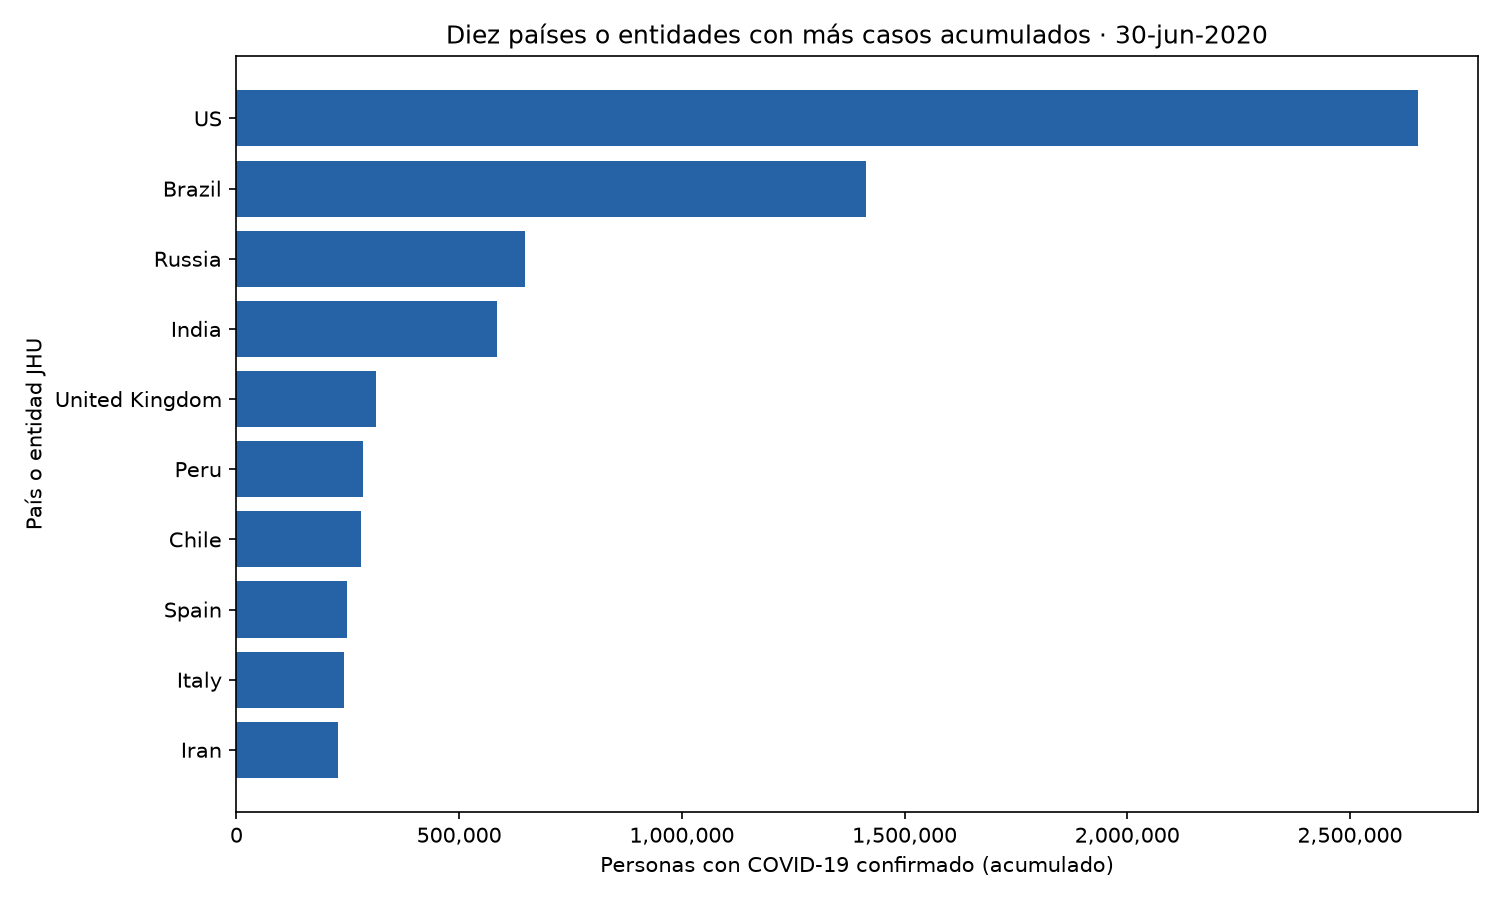

In [8]:
dia = df.loc[df.fecha_reporte.eq("2020-06-30")].copy()
assert not dia.duplicated(LLAVE).any()
niveles = dia.groupby("region_pais").provincia_estado.agg(
    nacional=lambda s: s.isna().any(), subnacional=lambda s: s.notna().any())
mezclas = set(niveles.index[niveles.nacional & niveles.subnacional])
# Casos revisados para esta fecha: territorio principal más dependencias separadas.
# No son filas total-país más sus regiones. Mostrar las filas evita ocultar la decisión.
assert mezclas == {"Denmark", "France", "Netherlands", "New Zealand"}
mostrar(dia.loc[dia.region_pais.isin(mezclas),
                ["region_pais", "provincia_estado", "confirmados", "fallecidos"]])
assert dia.confirmados.notna().all(), "Revisar conteos faltantes antes del ranking."
top10 = (dia.groupby("region_pais")["confirmados"].sum(min_count=1)
         .sort_values(ascending=False).head(10).rename_axis("país o entidad JHU").reset_index())
mostrar(top10)
assert top10.iloc[0].confirmados == 2653658
assert top10.iloc[6].tolist() == ["Chile", 279393]
FIGS.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10.iloc[::-1, 0], top10.iloc[::-1].confirmados, color="#2563a6")
ax.set(title="Diez países o entidades con más casos acumulados · 30-jun-2020",
       xlabel="Personas con COVID-19 confirmado (acumulado)", ylabel="País o entidad JHU")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(FIGS / "top10_2020-06-30.png", dpi=150)
mostrar(FIGS / "top10_2020-06-30.png")
plt.close(fig)


Estados Unidos encabeza el ranking con 2.653.658 casos; Chile ocupa el séptimo
lugar con 279.393. Estos conteos absolutos no comparan el riesgo de poblaciones
de diferente tamaño. Para ese objetivo se necesitan tasas, fuera de este análisis.


Chile: primera aparición 2020-03-03 | días regionales: 42


,filas,nacionales,regionales
fecha_reporte,,,
2020-05-18,1,1,0
2020-05-19,1,1,0
2020-05-20,17,0,17
2020-05-21,17,0,17
2020-05-22,17,0,17


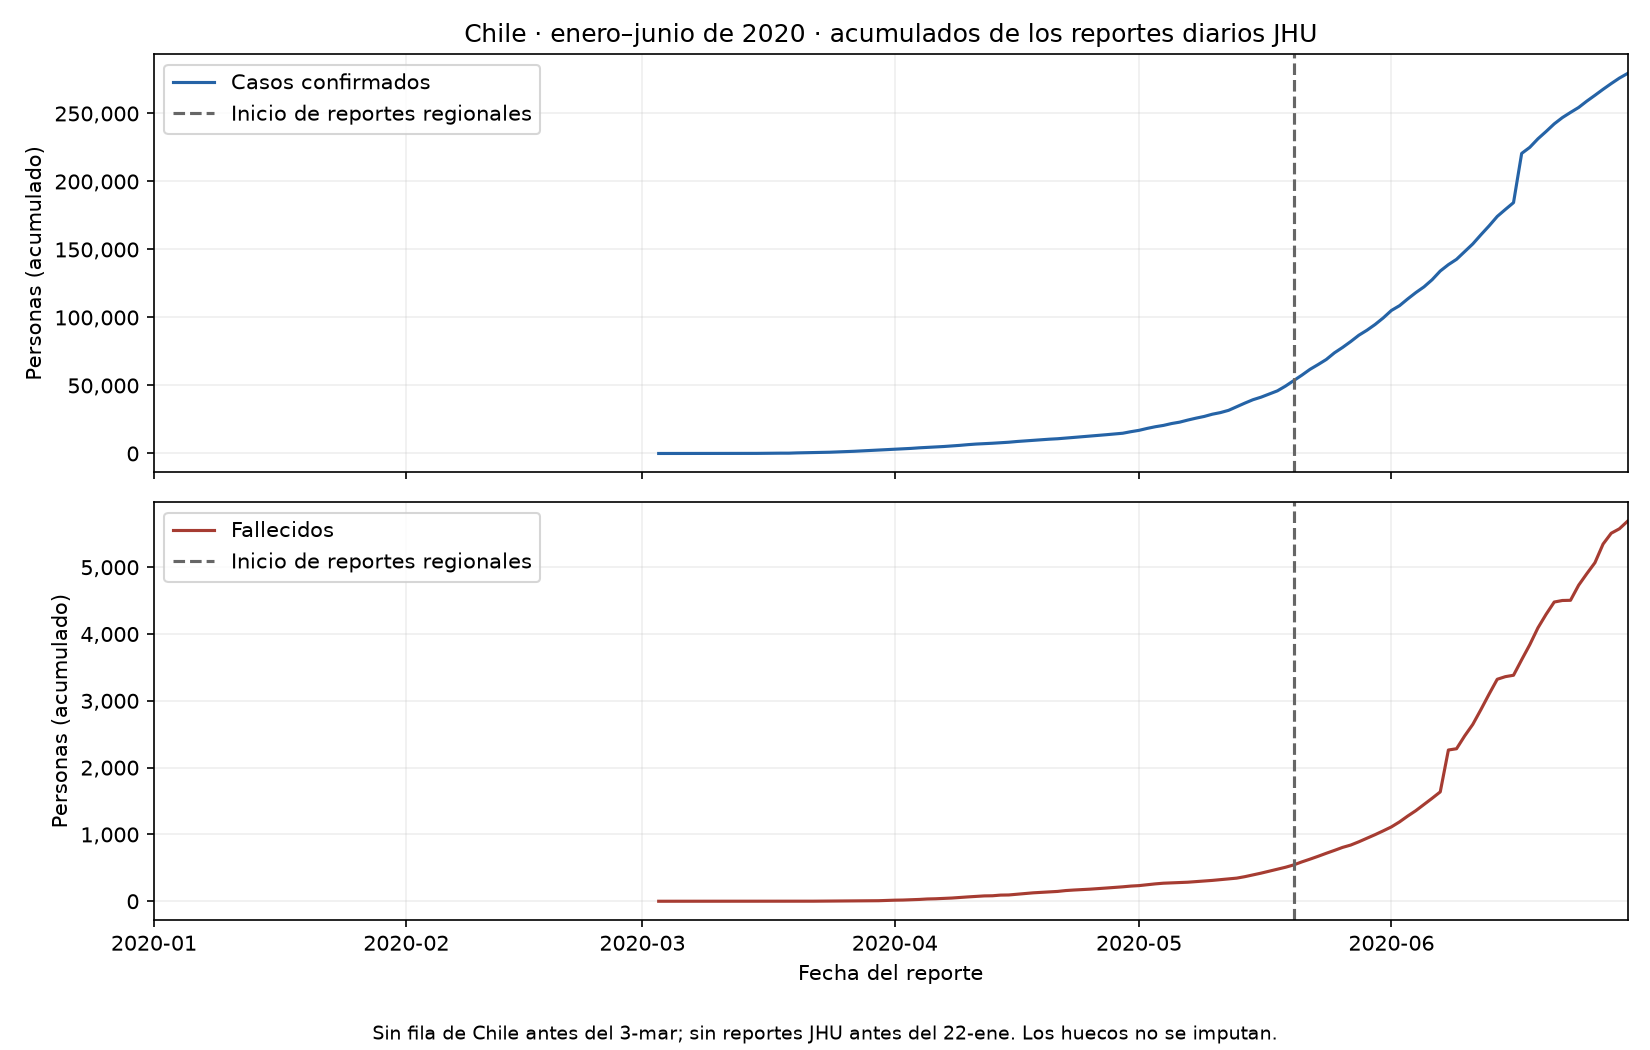

In [9]:
filas_chile = df.loc[df.region_pais.eq("Chile")].copy()
assert not filas_chile.duplicated(LLAVE).any()
granularidad_chile = filas_chile.groupby("fecha_reporte").agg(
    filas=("region_pais", "size"), nacionales=("provincia_estado", lambda s: s.isna().sum()),
    regionales=("provincia_estado", lambda s: s.notna().sum()))
antes = granularidad_chile.index < "2020-05-20"
assert granularidad_chile.loc[antes, "nacionales"].eq(1).all()
assert granularidad_chile.loc[antes, "regionales"].eq(0).all()
assert granularidad_chile.loc[~antes, "nacionales"].eq(0).all()
assert granularidad_chile.loc[~antes, "regionales"].eq(17).all()
assert filas_chile[["confirmados", "fallecidos"]].notna().all().all()
chile = filas_chile.groupby("fecha_reporte")[["confirmados", "fallecidos"]].sum(min_count=1)
assert chile.index.min() == "2020-03-03"
assert chile.loc["2020-06-30"].tolist() == [279393, 5688]
print("Chile: primera aparición", chile.index.min(), "| días regionales:", int((~antes).sum()))
mostrar(granularidad_chile.loc["2020-05-18":"2020-05-22"])
chile.index = pd.to_datetime(chile.index)
chile = chile.reindex(FECHAS)  # Ausencia como hueco: no inventar ceros.
fig, ejes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, columna, etiqueta, color in zip(ejes, ["confirmados", "fallecidos"],
                                      ["Casos confirmados", "Fallecidos"], ["#2563a6", "#a63c32"]):
    ax.plot(chile.index, chile[columna].astype(float), label=etiqueta, color=color)
    ax.axvline(pd.Timestamp("2020-05-20"), color="#666666", linestyle="--", label="Inicio de reportes regionales")
    ax.set_ylabel("Personas (acumulado)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
ejes[0].set_title("Chile · enero–junio de 2020 · acumulados de los reportes diarios JHU")
ejes[1].set_xlabel("Fecha del reporte")
ejes[1].set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-06-30"))
fig.text(0.5, 0.01, "Sin fila de Chile antes del 3-mar; sin reportes JHU antes del 22-ene. Los huecos no se imputan.",
         ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIGS / "chile_ene_jun2020.png", dpi=150)
mostrar(FIGS / "chile_ene_jun2020.png")
plt.close(fig)


Chile termina junio con 279.393 casos y 5.688 fallecidos acumulados. Hasta el
19-may se usa la fila nacional; desde el 20-may se suman 16 regiones y Unknown.
No hay fila nacional simultánea en esta ventana. No se reconstruyen regiones
anteriores ni se imputa cero antes del 3-mar. Los saltos pueden incluir revisiones:
no se atribuyen aquí a una causa epidemiológica ni se reemplazan por las series.


## 6. Perfilado automático
Se perfila la tabla completa de 19 columnas. Para comparar con el trabajo previo
se informa además la nulidad de sus 16 columnas, sin los tres campos nuevos de
preservación y origen. El modo minimal reduce cómputo; no sustituye los controles.


In [10]:
os.environ["YDATA_PROFILING_NO_ANALYTICS"] = "1"  # Perfilado local, sin telemetría externa.
try:
    from data_profiling import ProfileReport
    MOTOR_PERFILADO = "data_profiling"
except ImportError:
    from ydata_profiling import ProfileReport
    MOTOR_PERFILADO = "ydata_profiling"

PROFILE.mkdir(parents=True, exist_ok=True)
perfil = ProfileReport(df, title="Hito 1 · COVID-19 · enero–junio de 2020", minimal=True, progress_bar=False)
perfil.to_file(PROFILE / "perfilado_exploracion.html")
base_anterior = df.drop(columns=["ultima_actualizacion_original", "archivo_origen", "fila_origen"])
resumen = pd.Series({"archivos": len(inventario), "filas": len(df), "columnas_actuales": df.shape[1],
                     "columnas_base_anterior": base_anterior.shape[1],
                     "nulos_base_anterior_porcentaje": base_anterior.isna().mean().mean() * 100,
                     "nulos_actuales_porcentaje": df.isna().mean().mean() * 100,
                     "duplicados_llave_adicionales": duplicados_llave,
                     "duplicados_exactos_adicionales": duplicados_exactos})
mostrar(resumen)
print("Motor:", MOTOR_PERFILADO, "| perfilado:", PROFILE / "perfilado_exploracion.html")
assert abs(resumen.nulos_base_anterior_porcentaje - (633181 / (350945 * 16) * 100)) < 1e-8
assert (PROFILE / "perfilado_exploracion.html").stat().st_size > 1000


C:\Users\beaaa\OneDrive\Documents\Gestion-Datos-COVID19\proyecto gestion\.venv-hito1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/19 [00:00<?, ?it/s]

  5%|▌         | 1/19 [00:01<00:25,  1.41s/it]

 21%|██        | 4/19 [00:01<00:05,  2.74it/s]

100%|██████████| 19/19 [00:01<00:00, 10.47it/s]

archivos                             161.000000
filas                             350945.000000
columnas_actuales                     19.000000
columnas_base_anterior                16.000000
nulos_base_anterior_porcentaje        11.276357
nulos_actuales_porcentaje              9.495880
duplicados_llave_adicionales           3.000000
duplicados_exactos_adicionales         1.000000
dtype: float64

Motor: data_profiling | perfilado: C:\Users\beaaa\OneDrive\Documents\Gestion-Datos-COVID19\proyecto gestion\data\profile\perfilado_exploracion.html


### Tres observaciones fundamentadas
1. **Nulidad histórica:** las 16 columnas comparables tienen 11,2764% de celdas
   nulas. Coordenadas existen desde 1-mar; FIPS/Admin2/activos/clave desde 22-mar;
   tasas desde 29-may. La cobertura separa ausencia estructural y vacíos de origen:
   rellenarlos indiscriminadamente con cero alteraría el significado del conjunto.
   Se preservan tres textos literales "None" en provincia que la inferencia anterior
   convertía en NA: hay 633.181 vacíos en estas 16 columnas frente a 633.184 antes.
2. **Unicidad territorial:** hay tres repeticiones adicionales de la llave completa
   y una fila idéntica adicional, excluyendo archivo/fila de origen. District of
   Columbia contiene muertes contradictorias. Se conservan ambas versiones;
   el perfilado automático no decide cuál representa el valor correcto.
3. **Cambio territorial de Chile:** desde 20-may hay 42 días regionales con 16
   regiones y Unknown, sustituyendo la fila nacional. Se agregan sin superponer
   niveles y se verifican 279.393 casos y 5.688 muertes al 30-jun. La ausencia
   anterior al 3-mar no se convierte en cero.

**Alcance:** no se construyen Parquet, DW, fuentes externas, nuevos diarios,
modelos ni tablero. P7 sigue como propuesta. Roles nominales, publicación en
GitHub y confirmación EVA requieren evidencia del equipo.
